Project 2 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

In [13]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
df[numeric_cols].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [14]:
df[numeric_cols].agg(["count", "mean", "median"])

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.00000,1200.000,1200.0000
mean,2.945833,356.41275,5.485,1053.9683
median,3.000000,364.21000,5.000,823.6150


OUTLIERS

Quantity
Lower limit: -1.0
Upper limit: 7.0
Number of outliers: 0

UnitPrice
Lower limit: -317.1987499999999
Upper limit: 1024.8312499999997
Number of outliers: 0

ItemsInCart
Lower limit: -0.5
Upper limit: 11.5
Number of outliers: 0

TotalPrice
Lower limit: -1341.4125
Upper limit: 3330.4075
Number of outliers: 8



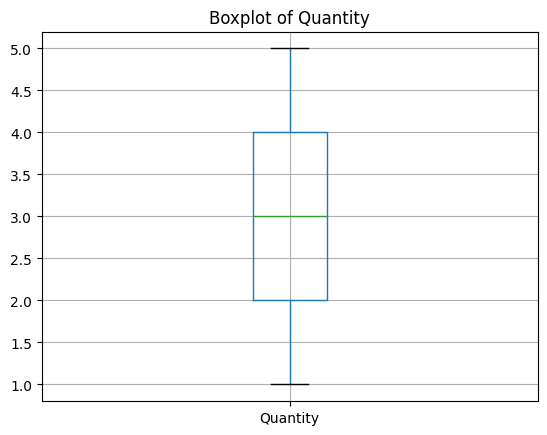

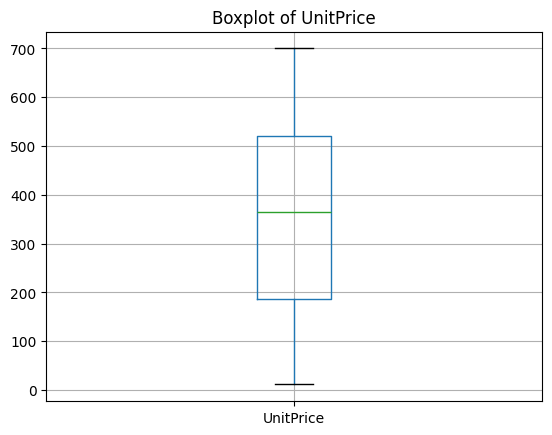

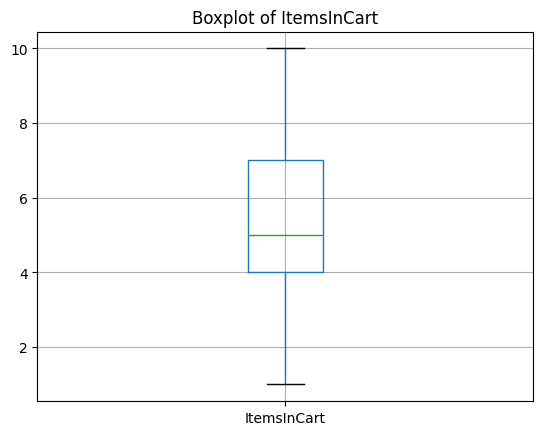

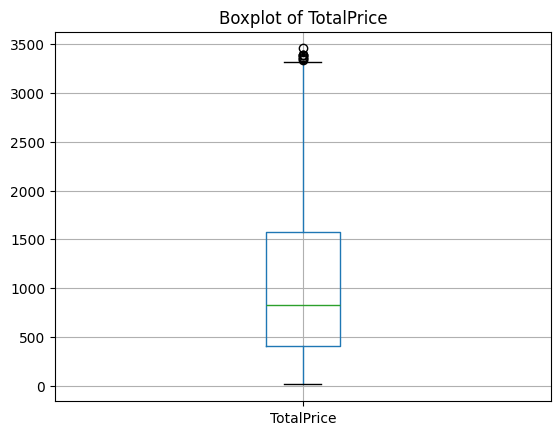

In [15]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))
    print()

for col in numeric_cols:
    df.boxplot(column=col)
    plt.title(f"Boxplot of {col}")
    plt.show()

DISTRIBUTION

Quantity

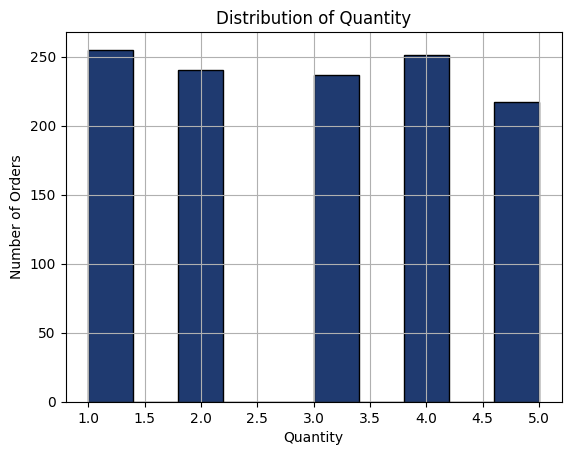

In [16]:
df["Quantity"].hist(bins=10)
plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Number of Orders")
df["Quantity"].hist(bins=10, color="#1F3A70", edgecolor="black")
plt.show()

Unit Price

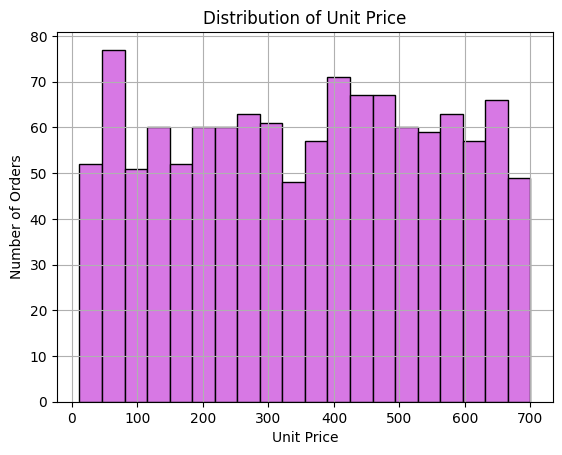

In [17]:
df["UnitPrice"].hist(bins=20)
plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Number of Orders")
df["UnitPrice"].hist(bins=20, color="#D778E4", edgecolor="black")
plt.show()

Items in Cart

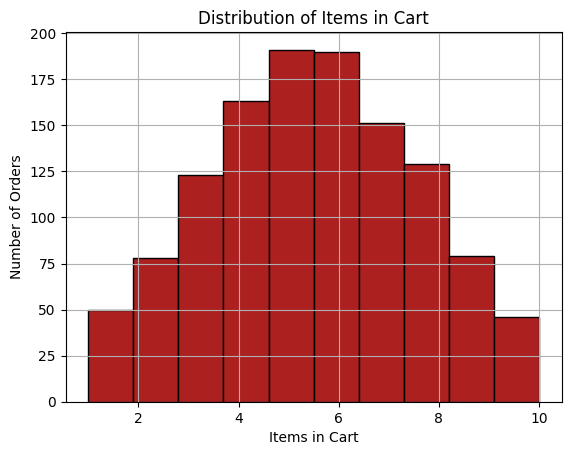

In [18]:
df["ItemsInCart"].hist(bins=10)
plt.title("Distribution of Items in Cart")
plt.xlabel("Items in Cart")
plt.ylabel("Number of Orders")
df["ItemsInCart"].hist(bins=10, color="#AC2020", edgecolor="black")
plt.show()

Total Price

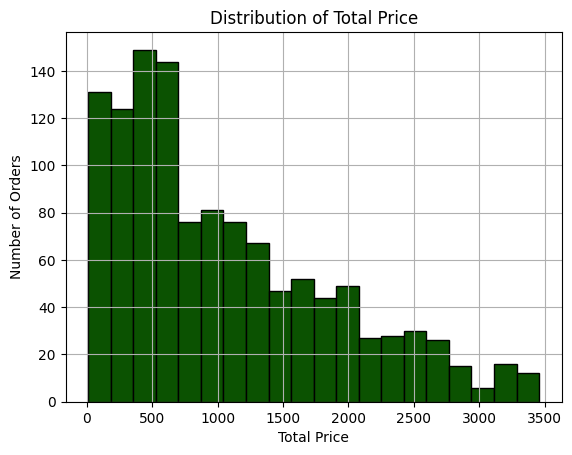

In [19]:
df["TotalPrice"].hist(bins=20)
plt.title("Distribution of Total Price")
plt.xlabel("Total Price")
plt.ylabel("Number of Orders")
df["TotalPrice"].hist(bins=20, color="#0B5201", edgecolor="black")
plt.show()

TRENDS

Monthly Order Trend

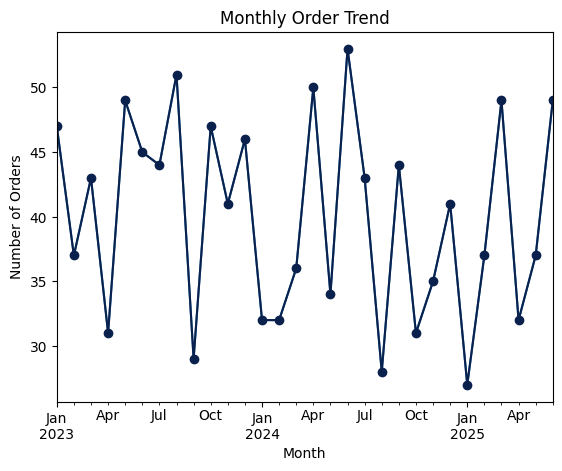

In [20]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_orders = df.groupby("Month").size()

monthly_orders.plot(kind="line")
plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
monthly_orders.plot(kind="line", color="#0B214D", marker="o")
plt.show()

Quantity Sold by Product

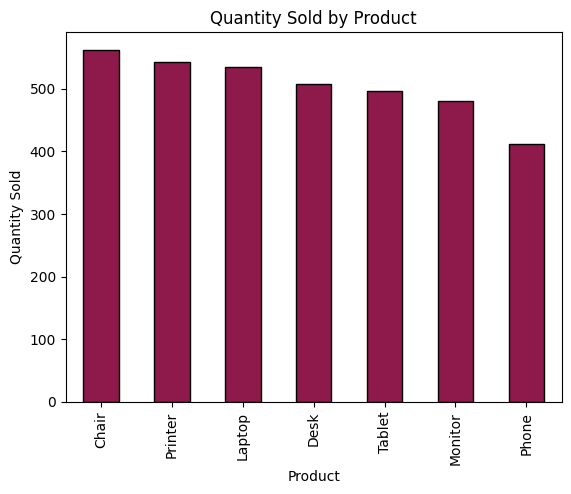

In [21]:
product_sales = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)

product_sales.plot(kind="bar")
plt.title("Quantity Sold by Product")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
product_sales.plot(kind="bar", color="#8D1A4A", edgecolor="black")
plt.show()

Orders by Payment Method

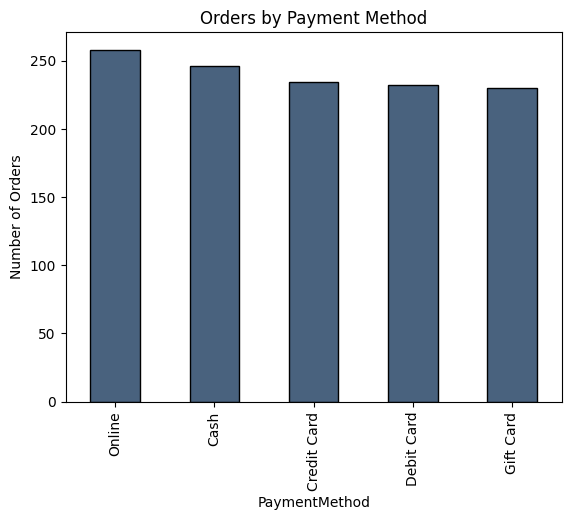

In [22]:
df["PaymentMethod"].value_counts().plot(kind="bar")

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
df["PaymentMethod"].value_counts().plot(kind="bar", color="#6E505088", edgecolor="black")
plt.show()

Order Status

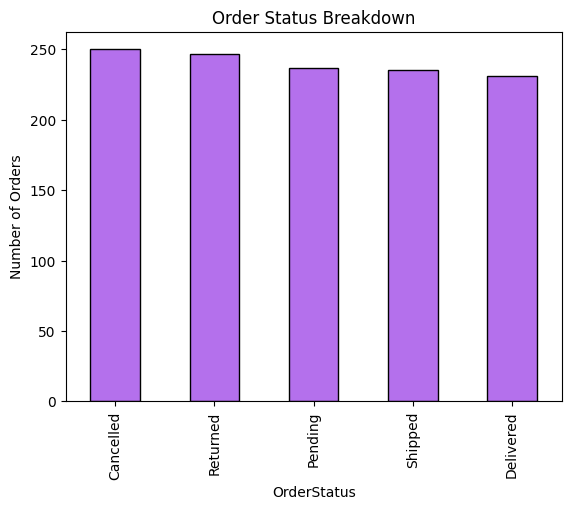

In [23]:
df["OrderStatus"].value_counts().plot(kind="bar")

plt.title("Order Status Breakdown")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
df["OrderStatus"].value_counts().plot(kind="bar", color="#B470EC", edgecolor="black")
plt.show()

Orders by Referral Source

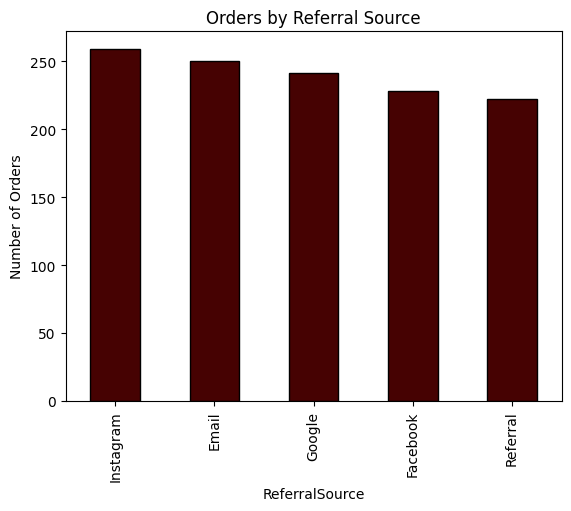

In [24]:
df["ReferralSource"].value_counts().plot(kind="bar")

plt.title("Orders by Referral Source")
plt.xlabel("Referral Source")
plt.ylabel("Number of Orders")
df["ReferralSource"].value_counts().plot(kind="bar", color="#460202", edgecolor="black")
plt.show()

CORRELATION

In [25]:
correlation = df[numeric_cols].corr()
correlation

,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000000,0.014553,0.650061,0.615251
UnitPrice,0.014553,1.000000,0.000602,0.717081
ItemsInCart,0.650061,0.000602,1.000000,0.392540
TotalPrice,0.615251,0.717081,0.392540,1.000000


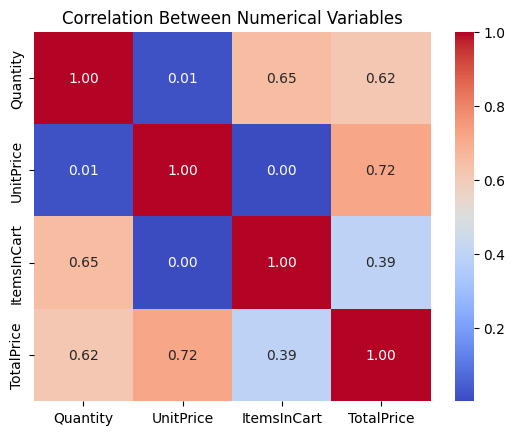

In [26]:
import seaborn as sns
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.show()

In [27]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
df[numeric_cols].agg(["count", "mean", "median"])

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.00000,1200.000,1200.0000
mean,2.945833,356.41275,5.485,1053.9683
median,3.000000,364.21000,5.000,823.6150


In [28]:
df.to_csv("cleaned_orders.csv", index=False)